## Check h5 cslcs

In [1]:
from pathlib import Path

import numpy as np
import rasterio
import matplotlib.pyplot as plt
import h5py

In [4]:
# Path to the first interferogram
cslc_file = Path(
    "/home/lukas/projects/ADUCAT/data/ISCE3/ASC_073/CSLC/t073_154936_iw1/20220101/t073_154936_iw1_20220101.h5"
)

In [5]:
with h5py.File(cslc_file, "r") as f:
    def print_dataset(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(
                f"{name}: shape={obj.shape}, "
                f"dtype={obj.dtype}"
            )

    f.visititems(print_dataset)

data/VV: shape=(4923, 19920), dtype=complex64
data/azimuth_carrier_phase: shape=(4923, 19920), dtype=float64
data/flattening_phase: shape=(4923, 19920), dtype=float64
data/projection: shape=(), dtype=int32
data/x_coordinates: shape=(19920,), dtype=float64
data/x_spacing: shape=(), dtype=float64
data/y_coordinates: shape=(4923,), dtype=float64
data/y_spacing: shape=(), dtype=float64
identification/absolute_orbit_number: shape=(), dtype=int64
identification/bounding_polygon: shape=(), dtype=|S1593
identification/burst_id: shape=(), dtype=|S15
identification/instrument_name: shape=(), dtype=|S5
identification/is_geocoded: shape=(), dtype=|S4
identification/look_direction: shape=(), dtype=|S5
identification/mission_id: shape=(), dtype=|S3
identification/orbit_pass_direction: shape=(), dtype=|S9
identification/processing_center: shape=(), dtype=|S25
identification/processing_date_time: shape=(), dtype=|S26
identification/product_level: shape=(), dtype=|S2
identification/product_specificatio

In [6]:
with h5py.File(cslc_file, "r") as f:
    ds = f["data/VV"]

    total = ds.size
    counts = {
        "exact_1_plus_0j": 0,
        "exact_zero": 0,
        "nonfinite": 0,
    }

    # Count suspicious values in manageable row chunks
    for row in range(0, ds.shape[0], 256):
        arr = ds[row:row + 256, :]

        counts["exact_1_plus_0j"] += np.count_nonzero(
            (arr.real == 1) & (arr.imag == 0)
        )
        counts["exact_zero"] += np.count_nonzero(
            (arr.real == 0) & (arr.imag == 0)
        )
        counts["nonfinite"] += np.count_nonzero(
            ~np.isfinite(arr.real) | ~np.isfinite(arr.imag)
        )

    print(f"Total pixels: {total:,}")

    for name, count in counts.items():
        print(f"{name}: {count:,} ({100 * count / total:.3f}%)")

    print("\nCSLC metadata:")
    for key in [
        "is_geocoded",
    ]:
        if key in f["identification"]:
            print(key, f["identification"][key][()])

    inputs = f["metadata/processing_information/inputs"]
    for key in [
        "burst_location_parameters/first_valid_line",
        "burst_location_parameters/last_valid_line",
        "burst_location_parameters/first_valid_sample",
        "burst_location_parameters/last_valid_sample",
    ]:
        print(key, inputs[key][()])

Total pixels: 98,066,160
exact_1_plus_0j: 0 (0.000%)
exact_zero: 0 (0.000%)
nonfinite: 63,119,018 (64.364%)

CSLC metadata:
is_geocoded b'True'
burst_location_parameters/first_valid_line 20
burst_location_parameters/last_valid_line 1482
burst_location_parameters/first_valid_sample 1057
burst_location_parameters/last_valid_sample 21477


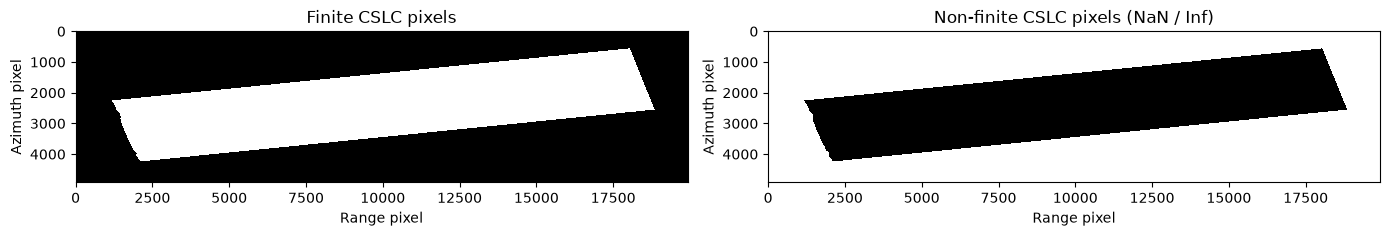

In [7]:
with h5py.File(cslc_file, "r") as f:
    ds = f["data/VV"]

    # Read the full validity mask, not the full complex array
    finite_mask = np.zeros(ds.shape, dtype=bool)

    for row in range(0, ds.shape[0], 256):
        arr = ds[row:row + 256, :]
        finite_mask[row:row + 256, :] = (
            np.isfinite(arr.real) & np.isfinite(arr.imag)
        )

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(finite_mask, cmap="gray", interpolation="nearest")
axes[0].set_title("Finite CSLC pixels")

axes[1].imshow(~finite_mask, cmap="gray", interpolation="nearest")
axes[1].set_title("Non-finite CSLC pixels (NaN / Inf)")

for ax in axes:
    ax.set_xlabel("Range pixel")
    ax.set_ylabel("Azimuth pixel")

plt.tight_layout()
plt.show()

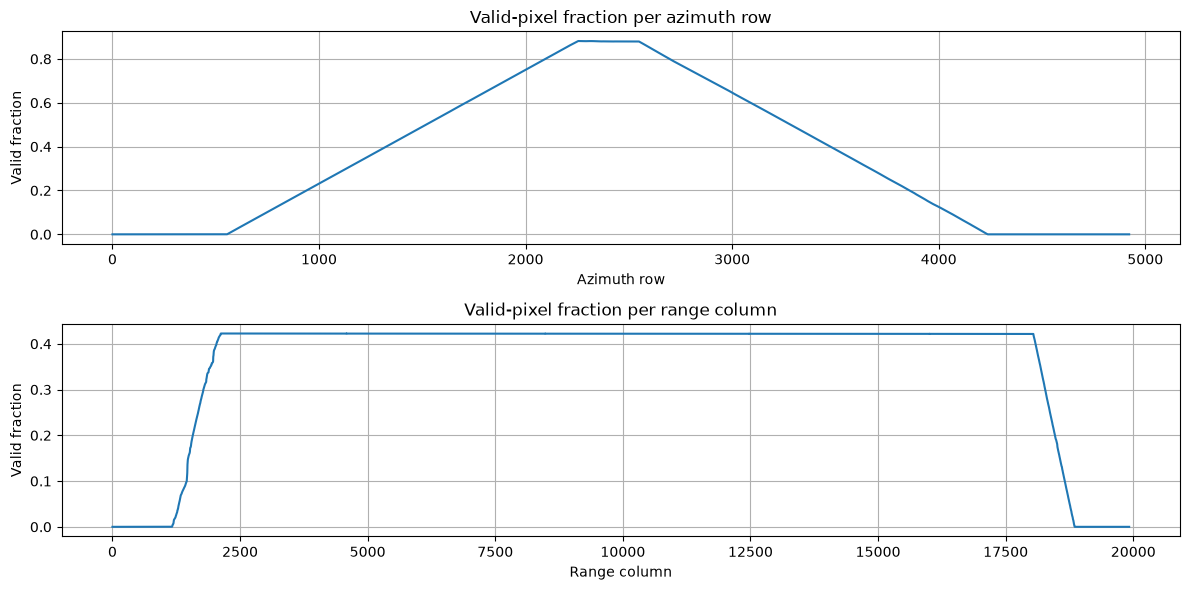

In [8]:
row_valid_fraction = finite_mask.mean(axis=1)
col_valid_fraction = finite_mask.mean(axis=0)

fig, axes = plt.subplots(2, 1, figsize=(12, 6))

axes[0].plot(row_valid_fraction)
axes[0].set_title("Valid-pixel fraction per azimuth row")
axes[0].set_xlabel("Azimuth row")
axes[0].set_ylabel("Valid fraction")
axes[0].grid(True)

axes[1].plot(col_valid_fraction)
axes[1].set_title("Valid-pixel fraction per range column")
axes[1].set_xlabel("Range column")
axes[1].set_ylabel("Valid fraction")
axes[1].grid(True)

plt.tight_layout()
plt.show()